In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d.art3d import Poly3DCollection
from matplotlib.collections import PolyCollection
from PIL import Image
from matplotlib.transforms import Affine2D
from scipy.ndimage import gaussian_filter, label

measured_tiff_path = Path(
    '/Users/yiyangzhi/Library/CloudStorage/'
    'GoogleDrive-yiyang_zhi3@berkeley.edu/Other computers/'
    'USB and External Devices/KINGSTON/trouble_shoot_focus/'
    'ca_2_3_2/edge_clear/2000X_3.tif'
)

In [2]:
# Change these values, then rerun this cell and the plotting cells below.
FONT_FAMILY = "Arial"  # Choose an installed font, e.g. "Arial" or "Times New Roman".
FONT_SIZE = 16  # points

plt.rcParams.update({
    "font.family": FONT_FAMILY,
    "savefig.dpi": 600,  # High resolution for exported images.
    "font.size": FONT_SIZE,
    "axes.titlesize": FONT_SIZE,
    "axes.labelsize": FONT_SIZE,
    "xtick.labelsize": FONT_SIZE,
    "ytick.labelsize": FONT_SIZE,
    "legend.fontsize": FONT_SIZE,
    "legend.title_fontsize": FONT_SIZE,
    "figure.titlesize": FONT_SIZE,
})

In [3]:
stl_path = Path(
    '/Users/yiyangzhi/Library/CloudStorage/'
    'GoogleDrive-yiyang_zhi3@berkeley.edu/My Drive/'
    'Ming Wu Integrated Photonics Group/Simulations/Fusion_360_Model/'
    'Integrated_Trapped_Ions_Library/FINAL/'
    'Ca_IPS_BFL153p2_f106um_FINAL_lens.STP.stl'
)

elev_deg = 0
azim_deg = 90

155,052 triangles; 77,528 unique vertices
Coordinates are in STL units; the STL format does not specify units.
X: -42.0004 to 42.0004 (span 84.0008)
Y: -5.00005 to 5.00005 (span 10.0001)
Z: 5.00007 to 25 (span 19.9999)


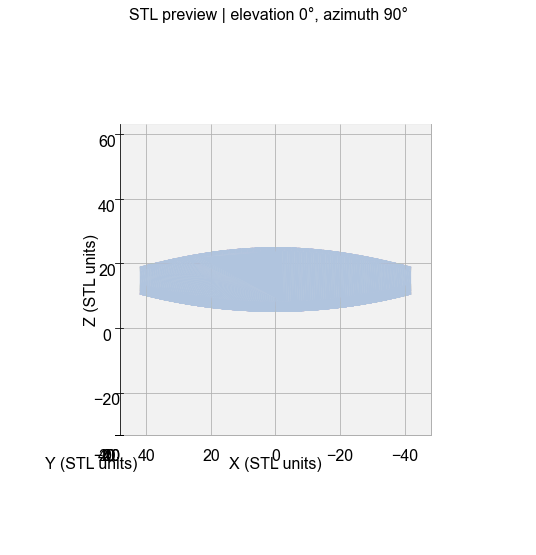

In [4]:
# Read this binary STL directly; no additional mesh package is needed.
triangle_dtype = np.dtype([
    ('normal', '<f4', (3,)),
    ('vertices', '<f4', (3, 3)),
    ('attribute', '<u2'),
])
with stl_path.open('rb') as stream:
    header = stream.read(80)
    count_bytes = stream.read(4)
    if len(count_bytes) != 4:
        raise ValueError('The STL header is incomplete.')
    triangle_count = int.from_bytes(count_bytes, byteorder='little')
    if stl_path.stat().st_size != 84 + 50 * triangle_count:
        raise ValueError('Expected a complete binary STL file.')
    records = np.fromfile(stream, dtype=triangle_dtype, count=triangle_count)

triangles = records['vertices'].astype(np.float64)
vertices = np.unique(triangles.reshape(-1, 3), axis=0)
bounds = np.array([vertices.min(axis=0), vertices.max(axis=0)])
extent = bounds[1] - bounds[0]
center = bounds.mean(axis=0)
print(f'{triangle_count:,} triangles; {len(vertices):,} unique vertices')
print('Coordinates are in STL units; the STL format does not specify units.')
for axis, low, high, span in zip('XYZ', bounds[0], bounds[1], extent):
    print(f'{axis}: {low:.6g} to {high:.6g} (span {span:.6g})')

fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')
ax.add_collection3d(Poly3DCollection(
    triangles, facecolor='lightsteelblue', edgecolor='none',
    linewidth=0, rasterized=True,
))
# Equal axis scales preserve the geometry; orthographic view avoids perspective distortion.
half_span = max(extent.max() * 0.55, 1e-9)
ax.set_xlim(center[0] - half_span, center[0] + half_span)
ax.set_ylim(center[1] - half_span, center[1] + half_span)
ax.set_zlim(center[2] - half_span, center[2] + half_span)
ax.set_box_aspect((1, 1, 1))
ax.set_proj_type('ortho')
ax.view_init(elev=elev_deg, azim=azim_deg)
ax.set(xlabel='X (STL units)', ylabel='Y (STL units)', zlabel='Z (STL units)')
ax.set_title(f'STL preview | elevation {elev_deg}°, azimuth {azim_deg}°')
plt.tight_layout()
plt.show()

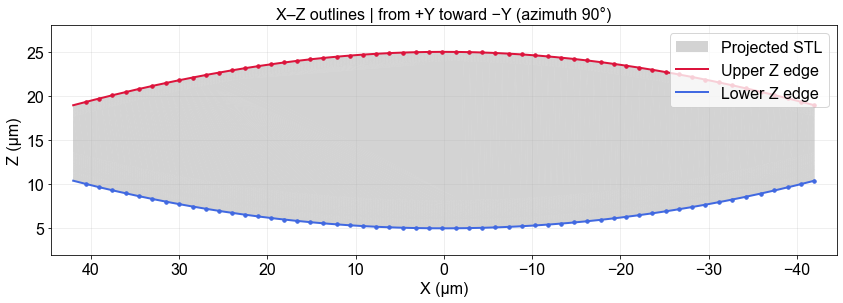

Top: 2,519 points in top_edge_xz_um, columns [X, Z] (µm)
Bottom: 2,519 points in bottom_edge_xz_um, columns [X, Z] (µm)
View: from +Y toward −Y. Saved coordinates remain physical [X, Z] in µm.


In [5]:
# X–Z silhouette from either side of Y, matching the 3D preview settings.


view_azimuth_deg = (float(azim_deg) + 180.0) % 360.0 - 180.0
if (not np.isfinite(float(elev_deg)) or not np.isfinite(view_azimuth_deg)
        or not np.isclose(float(elev_deg), 0.0, rtol=0, atol=1e-8)
        or not np.isclose(abs(view_azimuth_deg), 90.0, rtol=0, atol=1e-8)):
    raise ValueError('For an X–Z view, set elev_deg = 0 and azim_deg = -90 or +90.')
camera_y_sign = 1.0 if view_azimuth_deg > 0 else -1.0
view_direction_xyz = np.array([0.0, -camera_y_sign, 0.0])  # Camera toward object.
view_side_label = 'from +Y toward −Y' if camera_y_sign > 0 else 'from −Y toward +Y'

mesh_vertices_um, vertex_ids = np.unique(
    triangles.reshape(-1, 3), axis=0, return_inverse=True
)
face_ids = vertex_ids.reshape(-1, 3)
mesh_edges = np.concatenate([
    face_ids[:, [0, 1]], face_ids[:, [1, 2]], face_ids[:, [2, 0]],
])
mesh_edges.sort(axis=1)
unique_edges, edge_ids, edge_counts = np.unique(
    mesh_edges, axis=0, return_inverse=True, return_counts=True
)
face_normals = np.cross(
    triangles[:, 1] - triangles[:, 0], triangles[:, 2] - triangles[:, 0]
)
normal_along_view = face_normals @ view_direction_xyz
edge_face_signs = np.tile(np.sign(normal_along_view), 3)
min_sign = np.full(len(unique_edges), np.inf)
max_sign = np.full(len(unique_edges), -np.inf)
np.minimum.at(min_sign, edge_ids, edge_face_signs)
np.maximum.at(max_sign, edge_ids, edge_face_signs)
silhouette_mask = (min_sign < max_sign) | (edge_counts != 2)
silhouette_segments_um = mesh_vertices_um[unique_edges[silhouette_mask]]
if not len(silhouette_segments_um):
    raise ValueError('No silhouette edges found; check the mesh orientation.')

# Intersect candidate segments with vertical lines in the X–Z projection.
# Taking the outermost Z values removes internal/hidden silhouette candidates.
# Include every candidate endpoint X as well as a uniform sampling grid.
# The returned points are interpolated on mesh edges, not fitted curves.
x_samples_um = np.unique(np.concatenate([
    np.linspace(bounds[0, 0], bounds[1, 0], 2001),
    silhouette_segments_um[:, :, 0].ravel(),
]))
segment_start = silhouette_segments_um[:, 0][:, [0, 2]]
segment_end = silhouette_segments_um[:, 1][:, [0, 2]]
delta = segment_end - segment_start
x_tolerance_um = max(float(np.ptp(mesh_vertices_um[:, 0])), 1.0) * 1e-10
vertical = np.abs(delta[:, 0]) <= x_tolerance_um
x_low = np.minimum(segment_start[:, 0], segment_end[:, 0])
x_high = np.maximum(segment_start[:, 0], segment_end[:, 0])
top_z_um = np.full(x_samples_um.shape, np.nan)
bottom_z_um = np.full(x_samples_um.shape, np.nan)
for i, x_um in enumerate(x_samples_um):
    active = (~vertical) & (x_um >= x_low) & (x_um <= x_high)
    fraction = (x_um - segment_start[active, 0]) / delta[active, 0]
    z_hits = segment_start[active, 1] + fraction * delta[active, 1]
    # At vertical segments, include both endpoints to retain the extreme Z.
    at_vertical = vertical & (np.abs(x_um - segment_start[:, 0]) <= x_tolerance_um)
    z_hits = np.concatenate([
        z_hits, segment_start[at_vertical, 1], segment_end[at_vertical, 1],
    ])
    if z_hits.size:
        top_z_um[i] = z_hits.max()
        bottom_z_um[i] = z_hits.min()

# Each row is [X, Z] in µm. These are projected outline points; Y is collapsed.
top_edge_xz_um = np.column_stack([x_samples_um, top_z_um])
bottom_edge_xz_um = np.column_stack([x_samples_um, bottom_z_um])

fig_edges, ax_edges = plt.subplots(figsize=(12, 5))
ax_edges.add_collection(PolyCollection(
    triangles[:, :, [0, 2]], facecolors='lightgray', edgecolors='none',
    rasterized=True, label='Projected STL',
))
ax_edges.plot(*top_edge_xz_um.T, color='crimson', linewidth=2,
              label='Upper Z edge', zorder=3)
ax_edges.plot(*bottom_edge_xz_um.T, color='royalblue', linewidth=2,
              label='Lower Z edge', zorder=3)
# Sparse markers show sample locations without obscuring the outline.
marker_step = max(1, len(x_samples_um) // 55)
ax_edges.scatter(*top_edge_xz_um[::marker_step].T, color='crimson', s=12, zorder=4)
ax_edges.scatter(*bottom_edge_xz_um[::marker_step].T, color='royalblue', s=12, zorder=4)
ax_edges.autoscale_view()
ax_edges.margins(x=0.03, y=0.15)
ax_edges.set_aspect('equal', adjustable='box')
ax_edges.set(xlabel='X (µm)', ylabel='Z (µm)',
             title=f'X–Z outlines | {view_side_label} (azimuth {view_azimuth_deg:g}°)')
# A camera on +Y sees physical X increasing toward screen-left.
if camera_y_sign > 0:
    ax_edges.invert_xaxis()
ax_edges.grid(alpha=0.25)
ax_edges.legend(loc='upper right')
fig_edges.tight_layout()
plt.show()
print(f'Top: {np.isfinite(top_z_um).sum():,} points in top_edge_xz_um, columns [X, Z] (µm)')
print(f'Bottom: {np.isfinite(bottom_z_um).sum():,} points in bottom_edge_xz_um, columns [X, Z] (µm)')

print(f'View: {view_side_label}. Saved coordinates remain physical [X, Z] in µm.')


First theoretical surface ↔ STL bottom: X-weighted RMS = 0.00024773 µm (0.248 nm); max |difference| = 0.00057557 µm (0.576 nm).
Second theoretical surface ↔ STL top: X-weighted RMS = 0.00014950 µm (0.149 nm); max |difference| = 0.00040666 µm (0.407 nm).


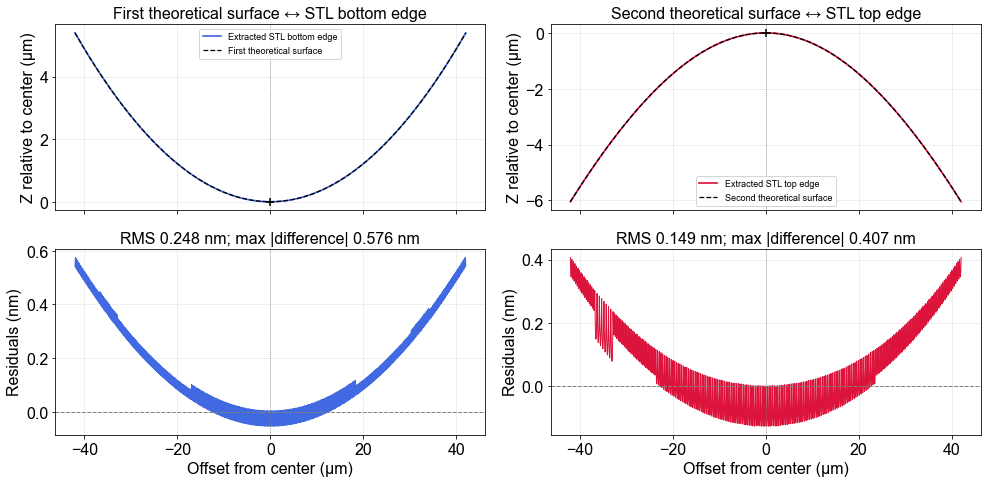

Comparison spans the full extracted STL aperture, with center translations only.
Small residuals can include STL faceting and rounding of the displayed design parameters.
Results retained in theory_stl_results; residual arrays are in µm.


In [6]:
# Shared theoretical parameters: first surface = TIFF top / STL lower Z;
# second surface = TIFF bottom / STL upper Z.
# First Biconic Zernike row -> TIFF top; second row -> TIFF bottom.
# Compare the X meridian (optical-design y = 0), with Max Zern Terms = 0:
# z(x) = (x²/Rx) / [1 + sqrt(1 - (1+kx)x²/Rx²)] + sum(a_n*x**n)
# X is SIGNED: retain odd powers, and especially the nonzero X² coefficient.
# Reference: https://ansyshelp.ansys.com/public/Views/Secured/Zemax/v25101/en/OpticStudio_User_Guide/OpticStudio_Help/topics/Biconic_Zernike.html
# Values are transcribed at the screenshot's displayed precision.
# ASSUMPTION: optical-design length units are µm, matching the STL/calibrated TIFF.
# a_n units: µm**(1-n). The screenshot does not show the model's unit setting.
# Visible X¹...X⁷ terms are included; higher offscreen terms are assumed zero.
# Max Zern Terms = 0, so Norm Radius = 1 does not scale the X-power coefficients.

asphere_parameters = {
    'first': {
        'radius_um': 921.224,
        'conic_constant': -61.805,
        'x_coefficients': {
            1: -6.053e-10, 2: 2.494e-3, 3: -5.128e-14,
            4: 2.190e-8, 5: -9.237e-18, 6: 0.0, 7: 0.0,
        },
    },
    'second': {
        'radius_um': -103.226,
        'conic_constant': -2.822,
        'x_coefficients': {
            1: -5.568e-10, 2: 1.095e-3, 3: -3.063e-14,
            4: -7.792e-11, 5: -7.024e-18, 6: 0.0, 7: 0.0,
        },
    },
}
# Signed radii already map these surfaces into the TIFF Y ordinate:
# first has positive sag; second has negative sag. No additional sign flip or fit.


def biconic_x_sag_um(x_um, radius_um, conic_constant, x_coefficients):
    """Biconic Zernike X-section at optical y=0, with zero Zernike terms."""
    x = np.asarray(x_um, dtype=float)
    radius = float(radius_um)
    k = float(conic_constant)
    if not np.isfinite(radius) or not np.isfinite(k):
        raise ValueError('Radius and conic constant must be finite.')
    curvature = 0.0 if radius == 0 else 1.0 / radius  # OpticStudio flat convention.
    coefficients = {}
    for power, coefficient in x_coefficients.items():
        if not isinstance(power, (int, np.integer)) or not 1 <= power <= 16:
            raise ValueError('X coefficient keys must be integer powers 1...16.')
        if not np.isfinite(float(coefficient)):
            raise ValueError('X coefficients must be finite.')
        coefficients[power] = float(coefficient)
    radicand = 1 - (1 + k) * (curvature * x)**2
    valid = np.isfinite(x) & (radicand >= 0)
    sag = np.full(x.shape, np.nan)
    sag[valid] = curvature * x[valid]**2 / (1 + np.sqrt(radicand[valid]))
    for power, coefficient in coefficients.items():
        sag[valid] += coefficient * x[valid]**power
    if not np.isfinite(sag[valid]).all():
        raise ValueError('Model overflow: check coefficient units and powers.')
    return sag

def center_profile(points_um):
    points = np.asarray(points_um, dtype=float)
    points = points[np.isfinite(points).all(axis=1)]
    points = points[np.argsort(points[:, 0])]
    if len(points) < 2:
        raise ValueError('At least two finite edge points are required.')
    center_x = (points[0, 0] + points[-1, 0]) / 2
    center_height = np.interp(center_x, points[:, 0], points[:, 1])
    center_point = np.array([center_x, center_height])
    return points - center_point, center_point

theory_stl_results = {}
fig_theory_stl, axes_theory_stl = plt.subplots(2, 2, figsize=(14, 7), sharex='col')
for column, (surface_name, stl_name, edge_points, color) in enumerate([
    ('first', 'bottom', bottom_edge_xz_um, 'royalblue'),
    ('second', 'top', top_edge_xz_um, 'crimson'),
]):
    centered_stl, stl_center = center_profile(edge_points)
    parameters = asphere_parameters[surface_name]
    arguments = (parameters['radius_um'], parameters['conic_constant'],
                 parameters['x_coefficients'])
    x_um = centered_stl[:, 0]
    theory_at_stl_um = biconic_x_sag_um(x_um, *arguments)
    difference_um = centered_stl[:, 1] - theory_at_stl_um
    if not np.isfinite(difference_um).all():
        raise ValueError(f'The theoretical {surface_name} surface is not valid over the full STL span.')
    # Weight RMS uniformly in X despite the nonuniform STL sampling stations.
    rms_um = np.sqrt(np.trapz(difference_um**2, x_um) / np.ptp(x_um))
    max_abs_um = np.max(np.abs(difference_um))
    dense_x_um = np.linspace(x_um[0], x_um[-1], 2001)
    profile_axis, residual_axis = axes_theory_stl[:, column]
    profile_axis.plot(*centered_stl.T, color=color, linewidth=1.7,
                      label=f'Extracted STL {stl_name} edge')
    profile_axis.plot(dense_x_um, biconic_x_sag_um(dense_x_um, *arguments),
                      'k--', linewidth=1.3, label=f'{surface_name.capitalize()} theoretical surface')
    profile_axis.scatter([0], [0], color='black', marker='+', s=60, zorder=5)
    profile_axis.set(title=f'{surface_name.capitalize()} theoretical surface ↔ STL {stl_name} edge',
                     ylabel='Z relative to center (µm)')
    profile_axis.legend(loc='best', fontsize=9)
    # Show tiny differences in nanometers; stored coordinates remain in µm.
    residual_axis.plot(x_um, 1000 * difference_um, color=color, linewidth=1)
    residual_axis.axhline(0, color='gray', linestyle='--', linewidth=1)
    residual_axis.set(xlabel='Offset from center (µm)', ylabel='Residuals (nm)',
                      title=f'RMS {1000*rms_um:.3f} nm; max |difference| {1000*max_abs_um:.3f} nm')
    for axis in (profile_axis, residual_axis):
        axis.axvline(0, color='gray', linestyle=':', linewidth=0.8)
        axis.grid(alpha=0.25)
    theory_stl_results[surface_name] = {
        'stl_edge': stl_name,
        'stl_center_xz_um': stl_center,
        'stl_centered_xz_um': centered_stl,
        'theory_at_stl_x_um': theory_at_stl_um,
        'difference_um': difference_um,
        'rms_um': rms_um,
        'max_abs_um': max_abs_um,
    }
    print(f'{surface_name.capitalize()} theoretical surface ↔ STL {stl_name}: '
          f'X-weighted RMS = {rms_um:.8f} µm ({1000*rms_um:.3f} nm); '
          f'max |difference| = {max_abs_um:.8f} µm ({1000*max_abs_um:.3f} nm).')
fig_theory_stl.tight_layout()
plt.show()
print('Comparison spans the full extracted STL aperture, with center translations only.')
print('Small residuals can include STL faceting and rounding of the displayed design parameters.')
print('Results retained in theory_stl_results; residual arrays are in µm.')


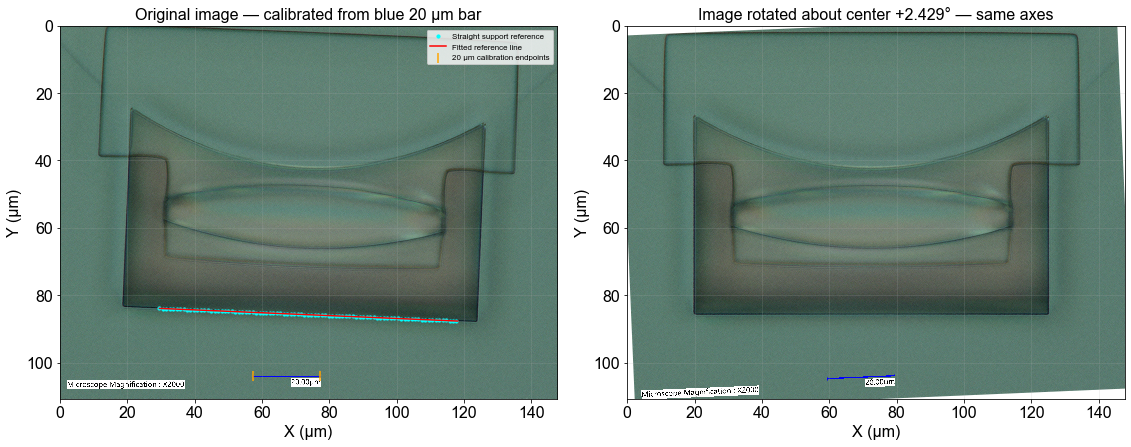

Scale bar: 390.0 pixels = 20 µm
Calibration: 0.05128205 µm/pixel (X and Y)
Applied rotation: +2.4289° (CCW positive); reference RMS: 0.485 pixels
Original pixel array retained unchanged: (2160, 2880, 3)
Ready: measured_rgb, measured_gray, measured_rotation_transform_um
Axes fixed to the original image grid in µm; Y increases downward.
Display transform only: no resampled array; image clipped to the original axes.


In [7]:
# Frame 0 is the full-resolution image; ignore the embedded secondary frame.
with Image.open(measured_tiff_path) as tiff:
    tiff.seek(0)
    measured_rgb = np.array(tiff.convert('RGB'))
measured_gray = measured_rgb.astype(float) @ np.array([0.2126, 0.7152, 0.0722]) / 255.0
image_height, image_width = measured_gray.shape

# Calibrate ORIGINAL image coordinates from the blue 20 µm scale bar.
# Measure between the centers of the vertical end ticks (not their outer edges).
scale_bar_length_um = 20.0
rgb_float = measured_rgb.astype(float)
red, green, blue = np.moveaxis(rgb_float, -1, 0)
blue_mask = (blue > 120) & (blue > red + 50) & (blue > green + 40)
blue_mask[:int(0.88 * image_height)] = False  # Footer containing the scale bar.
blue_labels, component_count = label(blue_mask)
if component_count == 0:
    raise ValueError('Blue scale bar not found in the image footer.')
component_sizes = np.bincount(blue_labels.ravel())
component_sizes[0] = 0
scale_bar_mask = blue_labels == component_sizes.argmax()
column_counts = scale_bar_mask.sum(axis=0)
end_tick_columns = np.flatnonzero(column_counts >= 0.65 * column_counts.max())
tick_groups = np.split(end_tick_columns, np.flatnonzero(np.diff(end_tick_columns) > 1) + 1)
if len(tick_groups) != 2:
    raise ValueError('Expected two blue scale-bar end ticks; inspect the detection.')
scale_bar_x_px = np.array([group.mean() for group in tick_groups])
scale_bar_y_px = float(np.flatnonzero(scale_bar_mask.any(axis=1)).mean())
scale_bar_length_px = float(np.diff(scale_bar_x_px)[0])
um_per_pixel = scale_bar_length_um / scale_bar_length_px
# Apply the same calibration to X and Y, assuming square microscope pixels.
measured_x_um = (np.arange(image_width) + 0.5) * um_per_pixel
measured_y_um = (np.arange(image_height) + 0.5) * um_per_pixel
image_extent_um = (0, image_width * um_per_pixel, image_height * um_per_pixel, 0)

# Estimate roll from the lower STRAIGHT SUPPORT edge, not the curved lens.
# Fractions of the original image: edit if using a different image/crop.
reference_x_fraction = (0.20, 0.80)
reference_y_fraction = (0.70, 0.83)
# Optional manual correction: positive = counterclockwise, negative = clockwise.
rotation_override_deg = None
x0, x1 = np.rint(np.array(reference_x_fraction) * image_width).astype(int)
y0, y1 = np.rint(np.array(reference_y_fraction) * image_height).astype(int)
if not (0 <= x0 < x1 <= image_width and 0 <= y0 < y1 <= image_height):
    raise ValueError('Reference ROI must lie within the image.')
vertical_gradient = np.abs(np.gradient(gaussian_filter(measured_gray, sigma=1.5), axis=0))
reference_x_px = np.arange(x0, x1, dtype=float)
reference_y_px = y0 + np.argmax(vertical_gradient[y0:y1, x0:x1], axis=0)

# Robust line fit rejects dust or other edges accidentally selected in the ROI.
reference_inliers = np.ones(reference_x_px.size, dtype=bool)
for _ in range(6):
    if reference_inliers.sum() < 20:
        raise ValueError('Too few reference points; adjust the reference ROI.')
    slope, intercept = np.polyfit(
        reference_x_px[reference_inliers], reference_y_px[reference_inliers], 1
    )
    residual = reference_y_px - (slope * reference_x_px + intercept)
    residual_center = np.median(residual[reference_inliers])
    residual_sigma = 1.4826 * np.median(np.abs(residual[reference_inliers] - residual_center))
    reference_inliers = np.abs(residual - residual_center) < max(3 * residual_sigma, 2.0)
if reference_inliers.sum() < 20:
    raise ValueError('Too few reference points; adjust the reference ROI.')
slope, intercept = np.polyfit(
    reference_x_px[reference_inliers], reference_y_px[reference_inliers], 1
)
estimated_rotation_deg = float(np.degrees(np.arctan(slope)))
rotation_deg = estimated_rotation_deg if rotation_override_deg is None else float(rotation_override_deg)
reference_fit_rms_px = float(np.sqrt(np.mean(
    (reference_y_px[reference_inliers] -
     (slope * reference_x_px[reference_inliers] + intercept)) ** 2
)))

# Rotate only the image artist about its center; keep the pixel arrays untouched.
# Coordinates have Y downward, so a visual CCW correction uses a negative angle.
image_center_um = np.array([image_width, image_height]) * um_per_pixel / 2
measured_rotation_transform_um = Affine2D().rotate_deg_around(
    *image_center_um, -rotation_deg
)
# For later edge extraction: detect points in the ORIGINAL image, convert [x,y]
# pixel centers to µm, then apply measured_rotation_transform_um.transform(points).
# No rotated/resampled image array is created.

fig_measured, axes_measured = plt.subplots(1, 2, figsize=(16, 7), sharex=True, sharey=True)
axes_measured[0].imshow(
    measured_rgb, extent=image_extent_um, origin='upper',
    interpolation='none', resample=False,
)
axes_measured[0].scatter(
    (reference_x_px[reference_inliers][::20] + 0.5) * um_per_pixel,
    (reference_y_px[reference_inliers][::20] + 0.5) * um_per_pixel,
    s=10, color='cyan', label='Straight support reference',
)
axes_measured[0].plot(
    (reference_x_px + 0.5) * um_per_pixel,
    (slope * reference_x_px + intercept + 0.5) * um_per_pixel,
    color='red', linewidth=1.5, label='Fitted reference line',
)
axes_measured[0].scatter(
    (scale_bar_x_px + 0.5) * um_per_pixel,
    np.full(2, (scale_bar_y_px + 0.5) * um_per_pixel),
    color='orange', marker='|', s=100, label='20 µm calibration endpoints',
)
axes_measured[0].set_title('Original image — calibrated from blue 20 µm bar')
axes_measured[0].legend(loc='upper right', fontsize=8)
measured_image_artist = axes_measured[1].imshow(
    measured_rgb, extent=image_extent_um, origin='upper',
    interpolation='none', resample=False,
    transform=measured_rotation_transform_um + axes_measured[1].transData,
    clip_on=True,
)
# Clip the rotated display to the same original coordinate window.
measured_image_artist.set_clip_path(axes_measured[1].patch)
axes_measured[1].set_title(f'Image rotated about center {rotation_deg:+.3f}° — same axes')
for axis in axes_measured:
    axis.set(xlabel='X (µm)', ylabel='Y (µm)',
             xlim=image_extent_um[:2], ylim=image_extent_um[2:])
    axis.set_aspect('equal')
    axis.tick_params(labelleft=True)
    axis.grid(alpha=0.2)
fig_measured.tight_layout()
plt.show()
print(f'Scale bar: {scale_bar_length_px:.1f} pixels = {scale_bar_length_um:g} µm')
print(f'Calibration: {um_per_pixel:.8f} µm/pixel (X and Y)')
print(f'Applied rotation: {rotation_deg:+.4f}° (CCW positive); reference RMS: {reference_fit_rms_px:.3f} pixels')
print(f'Original pixel array retained unchanged: {measured_rgb.shape}')
print('Ready: measured_rgb, measured_gray, measured_rotation_transform_um')
print('Axes fixed to the original image grid in µm; Y increases downward.')
print('Display transform only: no resampled array; image clipped to the original axes.')


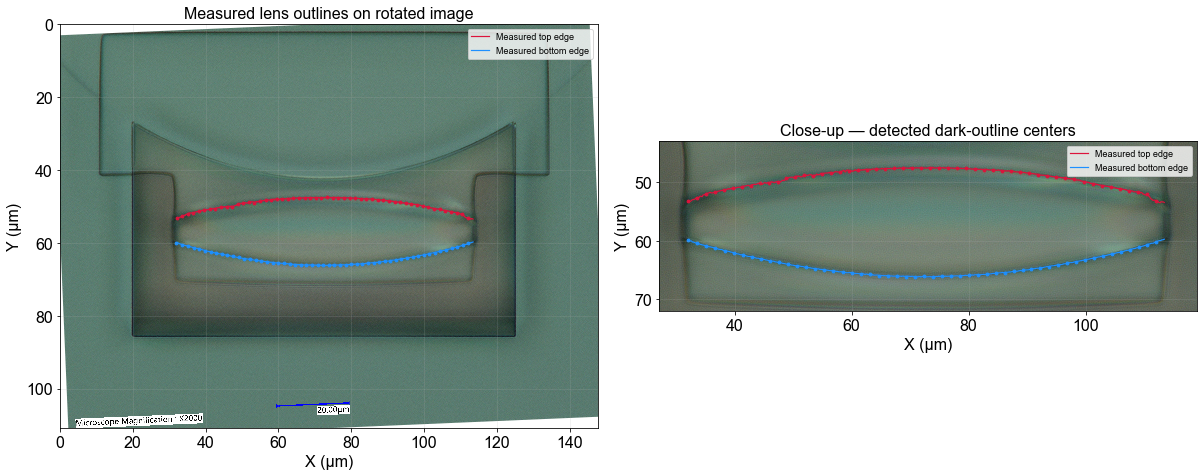

Top: 1,587 points → measured_top_edge_xy_um
Bottom: 1,588 points → measured_bottom_edge_xy_um
Columns: [X, Y] in µm, in the rotated view (Y downward).
Original pixel indices: measured_top_edge_pixels, measured_bottom_edge_pixels.
Traces follow dark-line centers; overlapping support junctions are excluded.


In [8]:
# Cell 4: trace the measured lens near (60, 60) µm on the rotated view.
# Detect dark-outline centers in ORIGINAL pixels, then rotate their coordinates.
# The image is never rotated into a new pixel array or interpolated.

lens_x_range_um = (32.0, 113.5)  # Avoid the overlapping vertical support edges.
top_search_y_um = (46.0, 56.0)
bottom_search_y_um = (58.0, 68.5)
# Positive response highlights narrow dark lines against the local background.
# Filtering is used only to locate edges; the displayed source image is unchanged.
dark_line_response = (
    gaussian_filter(measured_gray, sigma=7.0)
    - gaussian_filter(measured_gray, sigma=1.2)
)

def trace_lens_outline(y_range_um):
    """Return original integer [column,row] pixels and rotated [X,Y] µm points."""
    # Inverse-map the rotated search rectangle to bound ORIGINAL pixel indices.
    corners_um = np.array([
        [x, y] for x in lens_x_range_um for y in y_range_um
    ])
    original_corners_px = (
        measured_rotation_transform_um.inverted().transform(corners_um) / um_per_pixel - 0.5
    )
    col0, row0 = np.floor(original_corners_px.min(axis=0)).astype(int) - 2
    col1, row1 = np.ceil(original_corners_px.max(axis=0)).astype(int) + 3
    col0, col1 = max(col0, 0), min(col1, image_width)
    row0, row1 = max(row0, 0), min(row1, image_height)
    cols = np.arange(col0, col1)
    rows = np.arange(row0, row1)
    grid_col, grid_row = np.meshgrid(cols, rows)
    grid_xy_um = measured_rotation_transform_um.transform(
        (np.column_stack([grid_col.ravel(), grid_row.ravel()]) + 0.5) * um_per_pixel
    ).reshape(len(rows), len(cols), 2)
    in_band = ((grid_xy_um[:, :, 1] >= y_range_um[0]) &
               (grid_xy_um[:, :, 1] <= y_range_um[1]))
    response = dark_line_response[row0:row1, col0:col1].copy()
    response /= max(float(np.percentile(response[in_band], 95)), 1e-9)
    response[~in_band] = -np.inf

    # Follow one continuous dark ridge instead of independently jumping to a
    # different line in each column. Selected points remain integer source pixels.
    max_step_px = 3
    continuity_penalty = 0.06
    shifts = np.arange(-max_step_px, max_step_px + 1)
    row_indices = np.arange(len(rows))
    previous_rows = np.empty(response.shape, dtype=np.int32)
    cost = -response[:, 0]
    for col in range(1, len(cols)):
        choices = np.full((len(shifts), len(rows)), np.inf)
        for k, shift in enumerate(shifts):
            previous = row_indices + shift
            valid = (previous >= 0) & (previous < len(rows))
            choices[k, valid] = cost[previous[valid]] + continuity_penalty * shift**2
        best = np.argmin(choices, axis=0)
        previous_rows[:, col] = row_indices + shifts[best]
        cost = choices[best, row_indices] - response[:, col]
    if not np.isfinite(cost).any():
        raise ValueError('No continuous outline found; adjust the search bands.')
    path = np.empty(len(cols), dtype=int)
    path[-1] = np.argmin(cost)
    for col in range(len(cols) - 1, 0, -1):
        path[col - 1] = previous_rows[path[col], col]
    pixels = np.column_stack([cols, rows[path]])
    points_um = measured_rotation_transform_um.transform((pixels + 0.5) * um_per_pixel)
    keep = ((points_um[:, 0] >= lens_x_range_um[0]) &
            (points_um[:, 0] <= lens_x_range_um[1]))
    order = np.argsort(points_um[keep, 0])
    return pixels[keep][order], points_um[keep][order]

measured_top_edge_pixels, measured_top_edge_xy_um = trace_lens_outline(top_search_y_um)
measured_bottom_edge_pixels, measured_bottom_edge_xy_um = trace_lens_outline(bottom_search_y_um)
# Each coordinate array has columns [X,Y] in the ROTATED view, measured in µm.
# Y increases downward: the upper boundary has smaller Y than the lower boundary.

fig_lens_edges, axes_lens_edges = plt.subplots(1, 2, figsize=(17, 7))
for axis in axes_lens_edges:
    image_artist = axis.imshow(
        measured_rgb, extent=image_extent_um, origin='upper',
        interpolation='none', resample=False,
        transform=measured_rotation_transform_um + axis.transData, clip_on=True,
    )
    image_artist.set_clip_path(axis.patch)
    axis.plot(*measured_top_edge_xy_um.T, color='crimson', linewidth=1.2,
              label='Measured top edge')
    axis.plot(*measured_bottom_edge_xy_um.T, color='dodgerblue', linewidth=1.2,
              label='Measured bottom edge')
    axis.scatter(*measured_top_edge_xy_um[::30].T, color='crimson', s=8)
    axis.scatter(*measured_bottom_edge_xy_um[::30].T, color='dodgerblue', s=8)
    axis.set(xlabel='X (µm)', ylabel='Y (µm)')
    axis.set_aspect('equal')
    axis.grid(alpha=0.2)
    axis.legend(loc='upper right', fontsize=9)
axes_lens_edges[0].set(xlim=image_extent_um[:2], ylim=image_extent_um[2:],
                       title='Measured lens outlines on rotated image')
axes_lens_edges[1].set(xlim=(27, 119), ylim=(72, 43),
                       title='Close-up — detected dark-outline centers')
fig_lens_edges.tight_layout()
plt.show()
print(f'Top: {len(measured_top_edge_xy_um):,} points → measured_top_edge_xy_um')
print(f'Bottom: {len(measured_bottom_edge_xy_um):,} points → measured_bottom_edge_xy_um')
print('Columns: [X, Y] in µm, in the rotated view (Y downward).')
print('Original pixel indices: measured_top_edge_pixels, measured_bottom_edge_pixels.')
print('Traces follow dark-line centers; overlapping support junctions are excluded.')


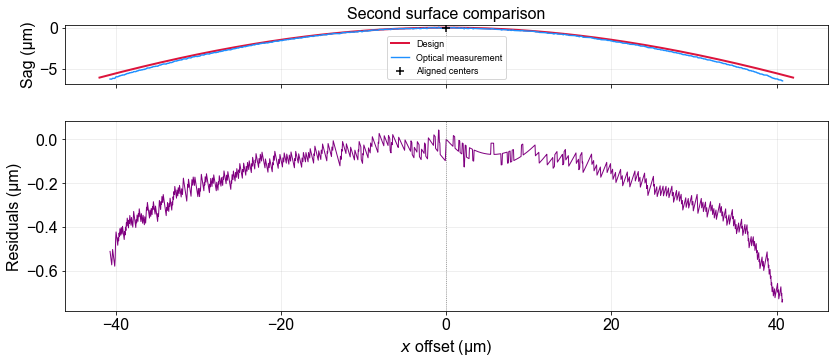

In [9]:
# Compare the TIFF bottom (blue) and STL top curves using center_profile defined above.
# Compare the opposing convex surfaces with the same crown orientation:
# use TIFF downward-positive Y and STL upward-positive Z as profile ordinates.
# Thus both centers are maxima. Relative to the TIFF display this reverses its
# vertical plotting direction; original numerical coordinates are unchanged.
# Align at the midpoint of each sampled X span; no scale or curvature fitting.

stl_top_centered_um, stl_profile_center_um = center_profile(top_edge_xz_um)
tiff_bottom_centered_um, tiff_profile_center_um = center_profile(measured_bottom_edge_xy_um)

# Evaluate the STL only within the shared X span to show TIFF − STL differences.
# This interpolates curve coordinates for comparison; no image pixels are resampled.
shared_x_min = max(stl_top_centered_um[0, 0], tiff_bottom_centered_um[0, 0])
shared_x_max = min(stl_top_centered_um[-1, 0], tiff_bottom_centered_um[-1, 0])
if shared_x_min >= shared_x_max:
    raise ValueError('The centered profiles have no overlapping X range.')
in_shared_span = ((tiff_bottom_centered_um[:, 0] >= shared_x_min) &
                  (tiff_bottom_centered_um[:, 0] <= shared_x_max))
comparison_x_um = tiff_bottom_centered_um[in_shared_span, 0]
stl_height_at_tiff_um = np.interp(
    comparison_x_um, stl_top_centered_um[:, 0], stl_top_centered_um[:, 1]
)
profile_difference_um = (
    tiff_bottom_centered_um[in_shared_span, 1] - stl_height_at_tiff_um
)

fig_profile_comparison, axes_profile_comparison = plt.subplots(
    2, 1, figsize=(12, 6), sharex=True, gridspec_kw={'height_ratios': [1, 1]},
)
overlay_axis, difference_axis = axes_profile_comparison
overlay_axis.plot(*stl_top_centered_um.T, color='crimson', linewidth=2,
                  label='Design')
overlay_axis.plot(*tiff_bottom_centered_um.T, color='dodgerblue', linewidth=1.4,
                  label='Optical measurement')
overlay_axis.scatter([0], [0], color='black', marker='+', s=80, zorder=5,
                     label='Aligned centers')
overlay_axis.set(ylabel='Sag (µm)',
                 title='Second surface comparison')
overlay_axis.set_aspect('equal', adjustable='box')
overlay_axis.legend(loc='lower center', fontsize=9)
difference_axis.plot(comparison_x_um, profile_difference_um, color='purple', linewidth=1)
difference_axis.set(xlabel='$x$ offset (µm)',
                    ylabel='Residuals (µm)')
for axis in axes_profile_comparison:
    axis.axvline(0, color='gray', linestyle=':', linewidth=0.8)
    axis.grid(alpha=0.25)
fig_profile_comparison.tight_layout()
plt.show()


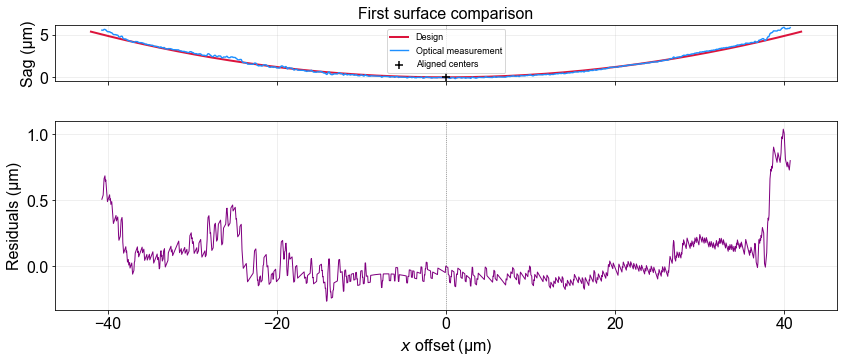

In [10]:
# First surface: TIFF top edge versus STL bottom (lower-Z) edge.
# Use TIFF Y and STL Z directly; both centered profiles have a minimum at the center.
# Align at the midpoint of each sampled X span; no scaling or curvature fitting.

stl_bottom_centered_um, stl_profile_center_um = center_profile(bottom_edge_xz_um)
tiff_top_centered_um, tiff_profile_center_um = center_profile(measured_top_edge_xy_um)

# Compare only within the shared X span.
# Interpolation applies to curve coordinates, not image pixels.
shared_x_min = max(stl_bottom_centered_um[0, 0], tiff_top_centered_um[0, 0])
shared_x_max = min(stl_bottom_centered_um[-1, 0], tiff_top_centered_um[-1, 0])
if shared_x_min >= shared_x_max:
    raise ValueError('The centered profiles have no overlapping X range.')

in_shared_span = (
    (tiff_top_centered_um[:, 0] >= shared_x_min)
    & (tiff_top_centered_um[:, 0] <= shared_x_max)
)
comparison_x_um = tiff_top_centered_um[in_shared_span, 0]
stl_height_at_tiff_um = np.interp(
    comparison_x_um,
    stl_bottom_centered_um[:, 0],
    stl_bottom_centered_um[:, 1],
)
profile_difference_um = (
    tiff_top_centered_um[in_shared_span, 1] - stl_height_at_tiff_um
)

fig_profile_comparison, axes_profile_comparison = plt.subplots(
    2, 1, figsize=(12, 6), sharex=True,
    gridspec_kw={'height_ratios': [1, 1]},
)
overlay_axis, difference_axis = axes_profile_comparison

overlay_axis.plot(
    *stl_bottom_centered_um.T, color='crimson', linewidth=2,
    label='Design',
)
overlay_axis.plot(
    *tiff_top_centered_um.T, color='dodgerblue', linewidth=1.4,
    label='Optical measurement',
)
overlay_axis.scatter(
    [0], [0], color='black', marker='+', s=80, zorder=5,
    label='Aligned centers',
)
overlay_axis.set(ylabel='Sag (µm)', title='First surface comparison')
overlay_axis.set_aspect('equal', adjustable='box')
overlay_axis.legend(loc='upper center', fontsize=9)

difference_axis.plot(
    comparison_x_um, profile_difference_um, color='purple', linewidth=1,
)
difference_axis.set(
    xlabel='$x$ offset (µm)',
    ylabel='Residuals (µm)',
)

for axis in axes_profile_comparison:
    axis.axvline(0, color='gray', linestyle=':', linewidth=0.8)
    axis.grid(alpha=0.25)

fig_profile_comparison.tight_layout()
plt.show()

First surface / TIFF top: RMS 0.2065 µm; max |difference| 1.0404 µm.
Second surface / TIFF bottom: RMS 0.2356 µm; max |difference| 0.7441 µm.


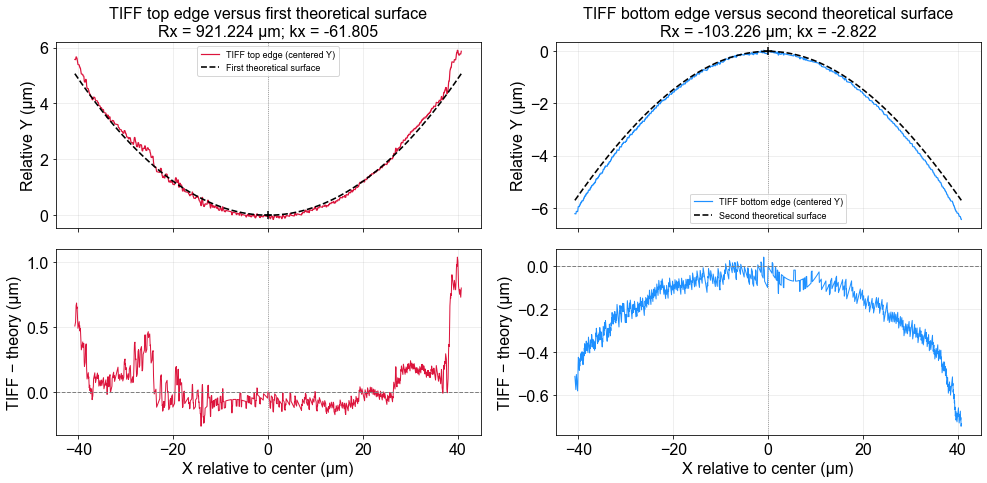

Assumptions: design units = µm; optical y = 0; offscreen higher X coefficients = 0.
Center translations only; supplied parameters unchanged; no image resampling.


In [11]:
# TIFF comparison using the first/second theoretical parameters defined above.
fig_asphere, axes_asphere = plt.subplots(2, 2, figsize=(14, 7), sharex='col')
asphere_comparison_results = {}
for column, (surface_name, edge_name, measured_edge, color) in enumerate([
    ('first', 'top', measured_top_edge_xy_um, 'crimson'),
    ('second', 'bottom', measured_bottom_edge_xy_um, 'dodgerblue'),
]):
    # Same center alignment as earlier comparisons: midpoint of sampled X span.
    measured_centered, measured_center = center_profile(measured_edge)
    parameters = asphere_parameters[surface_name]
    model_arguments = (parameters['radius_um'], parameters['conic_constant'],
                       parameters['x_coefficients'])
    theory_x_um = np.linspace(measured_centered[0, 0], measured_centered[-1, 0], 1501)
    theory_sag_um = biconic_x_sag_um(theory_x_um, *model_arguments)
    theory_at_points_um = biconic_x_sag_um(measured_centered[:, 0], *model_arguments)
    difference_um = measured_centered[:, 1] - theory_at_points_um
    valid = np.isfinite(difference_um)
    profile_axis, residual_axis = axes_asphere[:, column]
    profile_axis.plot(*measured_centered.T, color=color, linewidth=1.2,
                      label=f'TIFF {edge_name} edge (centered Y)')
    profile_axis.plot(theory_x_um, theory_sag_um, 'k--', linewidth=1.6,
                      label=f'{surface_name.capitalize()} theoretical surface')
    profile_axis.scatter([0], [0], color='black', marker='+', s=60, zorder=5)
    profile_axis.set(title=f'TIFF {edge_name} edge versus {surface_name} theoretical surface\n'
                     f'Rx = {parameters["radius_um"]:g} µm; kx = {parameters["conic_constant"]:g}',
                     ylabel='Relative Y (µm)')
    profile_axis.legend(loc='best', fontsize=9)
    residual_axis.plot(measured_centered[:, 0], difference_um, color=color, linewidth=1)
    residual_axis.axhline(0, color='gray', linestyle='--', linewidth=1)
    residual_axis.set(xlabel='X relative to center (µm)', ylabel='TIFF − theory (µm)')
    asphere_comparison_results[surface_name] = {
        'parameters': parameters,
        'measured_center_xy_um': measured_center,
        'measured_centered_xy_um': measured_centered,
        'theory_at_measured_x_um': theory_at_points_um,
        'difference_um': difference_um,
        'valid': valid,
    }
    if valid.any():
        rms_um = np.sqrt(np.mean(difference_um[valid]**2))
        max_abs_um = np.max(np.abs(difference_um[valid]))
        print(f'{surface_name.capitalize()} surface / TIFF {edge_name}: RMS {rms_um:.4f} µm; max |difference| {max_abs_um:.4f} µm.')
    if not valid.all():
        print(f'{edge_name.capitalize()}: {np.sum(~valid)} points outside the real conic domain; excluded.')
    for axis in (profile_axis, residual_axis):
        axis.axvline(0, color='gray', linestyle=':', linewidth=0.8)
        axis.grid(alpha=0.25)
fig_asphere.tight_layout()
plt.show()
print('Assumptions: design units = µm; optical y = 0; offscreen higher X coefficients = 0.')
print('Center translations only; supplied parameters unchanged; no image resampling.')
